# CS5488 · Flight-delay data analysis

**Member 2 analysis.** Source: BTS Reporting Carrier On-Time Performance, 2023–2025, using the cleaned Parquet files in the group's GitHub release `v0.1-data`. This notebook contains the computation and saved outputs. Put the three `otp_20XX.parquet` files in `data/` next to the notebook, or set `CS5488_DATA_DIR` to their folder before rerunning. The CSV and PNG deliverables are written to `member2_results/`.

In [1]:
"""CS5488 member 2: reproducible airport clustering and flight-delay rule mining.

The five predeparture rule dimensions are season, scheduled departure period,
week type, distance band, reporting airline, and origin state. Rules use up to
three dimensions and are selected only on 2023-24; 2025 is held out.
"""

from __future__ import annotations

import argparse
import os
import hashlib
import itertools
import json
import time
from pathlib import Path

import duckdb
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler


EXPECTED = {
    2023: (6_847_899, "9b3df5081e4cf9e2e00364db8ccf49fed17a4be08dccee01099836b48e35963b"),
    2024: (7_079_061, "94bacd0732a5c70c5d997acfee916e6727f83729cb9ae6c09061344666aebabf"),
    2025: (7_001_619, "a399e0b8571beee130c8d9a4fe2d36322a3e1d11a26ffb056ae3a9e1bcbc424a"),
}
REQUIRED_COLUMNS = {
    "Year", "Month", "DayOfWeek", "FlightDate", "Origin", "OriginCityName",
    "OriginState", "Reporting_Airline", "CRSDepHour", "Distance", "Cancelled",
    "Diverted", "ArrDel15", "ArrDelayMinutes", "LateAircraftDelay",
    "WeatherDelay", "TotalCauseDelay",
}
CLUSTER_FEATURES = [
    "delay_rate", "cancel_rate", "mean_delayed_min", "late_share", "weather_share"
]
RULE_DIMENSIONS = [
    "season", "dep_period", "week_type", "distance_band", "airline", "origin_state"
]




## 1 · Data audit and outcome definition

A delayed flight has `ArrDel15=1` (arrival at least 15 minutes late). The denominator excludes cancelled/diverted flights and missing `ArrDel15`. Cancellation rate uses all scheduled flights. The SHA-256 checks protect against using a different release without noticing.

In [2]:
def source_expr(data_dir: Path) -> str:
    paths = [data_dir / f"otp_{year}.parquet" for year in EXPECTED]
    missing = [str(p) for p in paths if not p.is_file()]
    if missing:
        raise FileNotFoundError("Missing Parquet files: " + ", ".join(missing))
    quoted = ["'" + str(p.resolve()).replace("'", "''") + "'" for p in paths]
    return "read_parquet([" + ", ".join(quoted) + "])"


def file_audit(db: duckdb.DuckDBPyConnection, data_dir: Path, source: str) -> pd.DataFrame:
    """Verify downloaded assets, schema and row totals before analysis."""
    available = {row[0] for row in db.execute(f"DESCRIBE SELECT * FROM {source}").fetchall()}
    absent = REQUIRED_COLUMNS - available
    if absent:
        raise ValueError("Required columns missing: " + ", ".join(sorted(absent)))
    actual_rows = dict(db.execute(f"SELECT Year, count(*) FROM {source} GROUP BY Year").fetchall())
    if set(actual_rows) != set(EXPECTED):
        raise ValueError(f"Unexpected years: {actual_rows}")
    records = []
    for year, (expected_rows, expected_hash) in EXPECTED.items():
        path = data_dir / f"otp_{year}.parquet"
        h = hashlib.sha256()
        with path.open("rb") as stream:
            for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
                h.update(block)
        digest = h.hexdigest()
        count = actual_rows[year]
        if digest != expected_hash or count != expected_rows:
            raise ValueError(f"Asset check failed for {path.name}: rows={count}, sha256={digest}")
        records.append({"year": year, "rows": count, "bytes": path.stat().st_size,
                        "sha256": digest, "verified": True})
    return pd.DataFrame(records)


def annual_overview(db: duckdb.DuckDBPyConnection, source: str) -> pd.DataFrame:
    result = db.execute(f"""
        SELECT Year AS year, count(*) AS scheduled,
               count(*) FILTER (WHERE Cancelled=1) AS cancelled,
               count(*) FILTER (WHERE Diverted=1) AS diverted,
               count(*) FILTER (WHERE Cancelled=0 AND Diverted=0 AND ArrDel15 IS NULL)
                   AS executed_missing_arrdel15,
               count(*) FILTER (WHERE Cancelled=0 AND Diverted=0 AND ArrDel15 IS NOT NULL)
                   AS delay_denominator,
               count(*) FILTER (WHERE Cancelled=0 AND Diverted=0 AND ArrDel15=1)
                   AS delayed
        FROM {source} GROUP BY Year ORDER BY Year
    """).df()
    result["delay_rate"] = result.delayed / result.delay_denominator
    result["cancel_rate"] = result.cancelled / result.scheduled
    if not (result.scheduled.sum() == 20_928_579 and
            result.delay_denominator.sum() == 20_588_134 and
            result.delayed.sum() == 4_371_303):
        raise ValueError("Annual totals no longer match the verified release")
    return result

In [3]:
DATA_DIR = Path(os.environ.get('CS5488_DATA_DIR', 'data'))
OUT_DIR = Path('member2_results')
OUT_DIR.mkdir(exist_ok=True)
db = duckdb.connect()
db.execute('SET threads=4')
source = source_expr(DATA_DIR)
audit = file_audit(db, DATA_DIR, source)
yearly = annual_overview(db, source)
audit.to_csv(OUT_DIR / 'data_audit.csv', index=False)
yearly.to_csv(OUT_DIR / 'yearly_overview.csv', index=False)
print('Verified files:')
print(audit.to_string(index=False))
print('\nAnnual overview:')
print(yearly.to_string(index=False))

Verified files:
 year    rows     bytes                                                           sha256  verified
 2023 6847899 197988418 9b3df5081e4cf9e2e00364db8ccf49fed17a4be08dccee01099836b48e35963b      True
 2024 7079061 194491863 94bacd0732a5c70c5d997acfee916e6727f83729cb9ae6c09061344666aebabf      True
 2025 7001619 205002828 a399e0b8571beee130c8d9a4fe2d36322a3e1d11a26ffb056ae3a9e1bcbc424a      True

Annual overview:
 year  scheduled  cancelled  diverted  executed_missing_arrdel15  delay_denominator  delayed  delay_rate  cancel_rate
 2023    6847899      87943     16552                          1            6743403  1386699    0.205638     0.012842
 2024    7079061      96315     17499                          0            6965247  1449966    0.208172     0.013606
 2025    7001619     102876     19258                          1            6879484  1534638    0.223075     0.014693


## 2 · Airport profiles and clustering

Five features describe each **departure airport's flights**: arrival-delay rate, cancellation rate, mean minutes among delayed arrivals, and the shares of cause minutes attributed to late aircraft and weather. Only airports with at least 30,000 scheduled flights are clustered. Even at a 50% rate, that sample size gives a worst-case binomial 95% margin of about ±0.57 percentage points for a simple proportion. The threshold was set after exploratory inspection identified a small-volume outlier, so sensitivity is essential. Features are standardized before KMeans; k is compared from 2 to 6. Threshold sensitivity is reported.

In [4]:
def airport_profiles(db: duckdb.DuckDBPyConnection, source: str) -> pd.DataFrame:
    profiles = db.execute(f"""
        SELECT Origin AS airport, min(OriginCityName) AS city,
               count(*) AS scheduled,
               count(*) FILTER (WHERE Cancelled=0 AND Diverted=0 AND ArrDel15 IS NOT NULL)
                   AS delay_denominator,
               count(*) FILTER (WHERE Cancelled=0 AND Diverted=0 AND ArrDel15=1) AS delayed,
               count(*) FILTER (WHERE Cancelled=1) AS cancelled,
               sum(ArrDelayMinutes) FILTER (WHERE ArrDel15=1) AS delayed_arrival_minutes,
               sum(LateAircraftDelay) AS late_minutes,
               sum(WeatherDelay) AS weather_minutes,
               sum(TotalCauseDelay) AS cause_minutes
        FROM {source} GROUP BY Origin
    """).df()
    profiles["delay_rate"] = profiles.delayed / profiles.delay_denominator
    profiles["cancel_rate"] = profiles.cancelled / profiles.scheduled
    profiles["mean_delayed_min"] = profiles.delayed_arrival_minutes / profiles.delayed
    profiles["late_share"] = profiles.late_minutes / profiles.cause_minutes
    profiles["weather_share"] = profiles.weather_minutes / profiles.cause_minutes
    return profiles.sort_values("scheduled", ascending=False).reset_index(drop=True)


def cluster_airports(profiles: pd.DataFrame, out: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Use an explicit minimum volume and report threshold sensitivity."""
    eligible = profiles.loc[profiles.scheduled >= 30_000].dropna(subset=CLUSTER_FEATURES).copy()
    if len(eligible) != 101:
        raise ValueError(f"Unexpected number of eligible airports: {len(eligible)}")
    scaler = StandardScaler()
    X = scaler.fit_transform(eligible[CLUSTER_FEATURES])
    candidates = []
    for k in range(2, 7):
        model = KMeans(n_clusters=k, n_init=50, random_state=5488)
        labels = model.fit_predict(X)
        candidates.append({"k": k, "silhouette": silhouette_score(X, labels),
                           "smallest_cluster": int(np.bincount(labels).min())})
    diagnostics = pd.DataFrame(candidates)
    allowed = diagnostics.loc[diagnostics.smallest_cluster >= 5]
    best_k = int(allowed.sort_values("silhouette", ascending=False).iloc[0].k)
    model = KMeans(n_clusters=best_k, n_init=50, random_state=5488)
    eligible["cluster"] = model.fit_predict(X) + 1
    eligible.to_csv(out / "airport_clusters.csv", index=False)

    summary = eligible.groupby("cluster").agg(
        airports=("airport", "size"), scheduled=("scheduled", "sum"),
        delay_denominator=("delay_denominator", "sum"), delayed=("delayed", "sum"),
        cancelled=("cancelled", "sum"), delay_rate=("delay_rate", "mean"),
        cancel_rate=("cancel_rate", "mean"), mean_delayed_min=("mean_delayed_min", "mean"),
        late_share=("late_share", "mean"), weather_share=("weather_share", "mean"),
    ).reset_index()
    summary["flight_weighted_delay_rate"] = summary.delayed / summary.delay_denominator
    summary["flight_weighted_cancel_rate"] = summary.cancelled / summary.scheduled
    summary.to_csv(out / "cluster_summary.csv", index=False)

    # Refit on alternate volume thresholds; compare common airports, not numeric labels.
    base = eligible.set_index("airport")["cluster"]
    threshold_rows = []
    for threshold in (20_000, 30_000, 50_000):
        q = profiles.loc[profiles.scheduled >= threshold].dropna(subset=CLUSTER_FEATURES)
        xx = StandardScaler().fit_transform(q[CLUSTER_FEATURES])
        labels = KMeans(n_clusters=best_k, n_init=50, random_state=5488).fit_predict(xx)
        alternate = pd.Series(labels, index=q.airport)
        common = base.index.intersection(alternate.index)
        threshold_rows.append({"minimum_scheduled": threshold, "airports": len(q),
                               "flight_coverage": q.scheduled.sum() / profiles.scheduled.sum(),
                               "silhouette": silhouette_score(xx, labels),
                               "smallest_cluster": int(np.bincount(labels).min()),
                               "ari_vs_30000": adjusted_rand_score(base[common], alternate[common])})
    sensitivity = pd.DataFrame(threshold_rows)
    sensitivity.to_csv(out / "cluster_sensitivity.csv", index=False)
    diagnostics.to_csv(out / "cluster_k_diagnostics.csv", index=False)

    pca = PCA(n_components=2, random_state=5488)
    xy = pca.fit_transform(X)
    fig, ax = plt.subplots(figsize=(9, 6))
    for cluster, group in eligible.groupby("cluster"):
        idx = eligible.index.get_indexer(group.index)
        ax.scatter(xy[idx, 0], xy[idx, 1], s=np.sqrt(group.scheduled) / 8,
                   alpha=.7, label=f"Group {cluster} ({len(group)} airports)")
    for _, row in eligible.nlargest(10, "scheduled").iterrows():
        idx = eligible.index.get_loc(row.name)
        ax.annotate(row.airport, xy[idx], xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
           ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)",
           title="Departure-airport profiles, 2023–2025")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(out / "airport_clusters.png", dpi=250)
    plt.close(fig)
    return eligible, summary, diagnostics

K choice:
 k  silhouette  smallest_cluster
 2       0.261                43
 3       0.265                30
 4       0.229                18
 5       0.254                11
 6       0.261                 8

Cluster summary:
 cluster  airports  scheduled  delay_denominator  delayed  cancelled  delay_rate  cancel_rate  mean_delayed_min  late_share  weather_share  flight_weighted_delay_rate  flight_weighted_cancel_rate
       1        37    7836870            7738740  1570914      79107       0.186        0.010            63.227       0.437          0.038                       0.203                        0.010
       2        30    3483214            3435223   658056      39583       0.187        0.013            78.617       0.347          0.080                       0.192                        0.011
       3        34    7896295            7734784  1815776     140602       0.218        0.017            78.559       0.427          0.049                       0.235                    

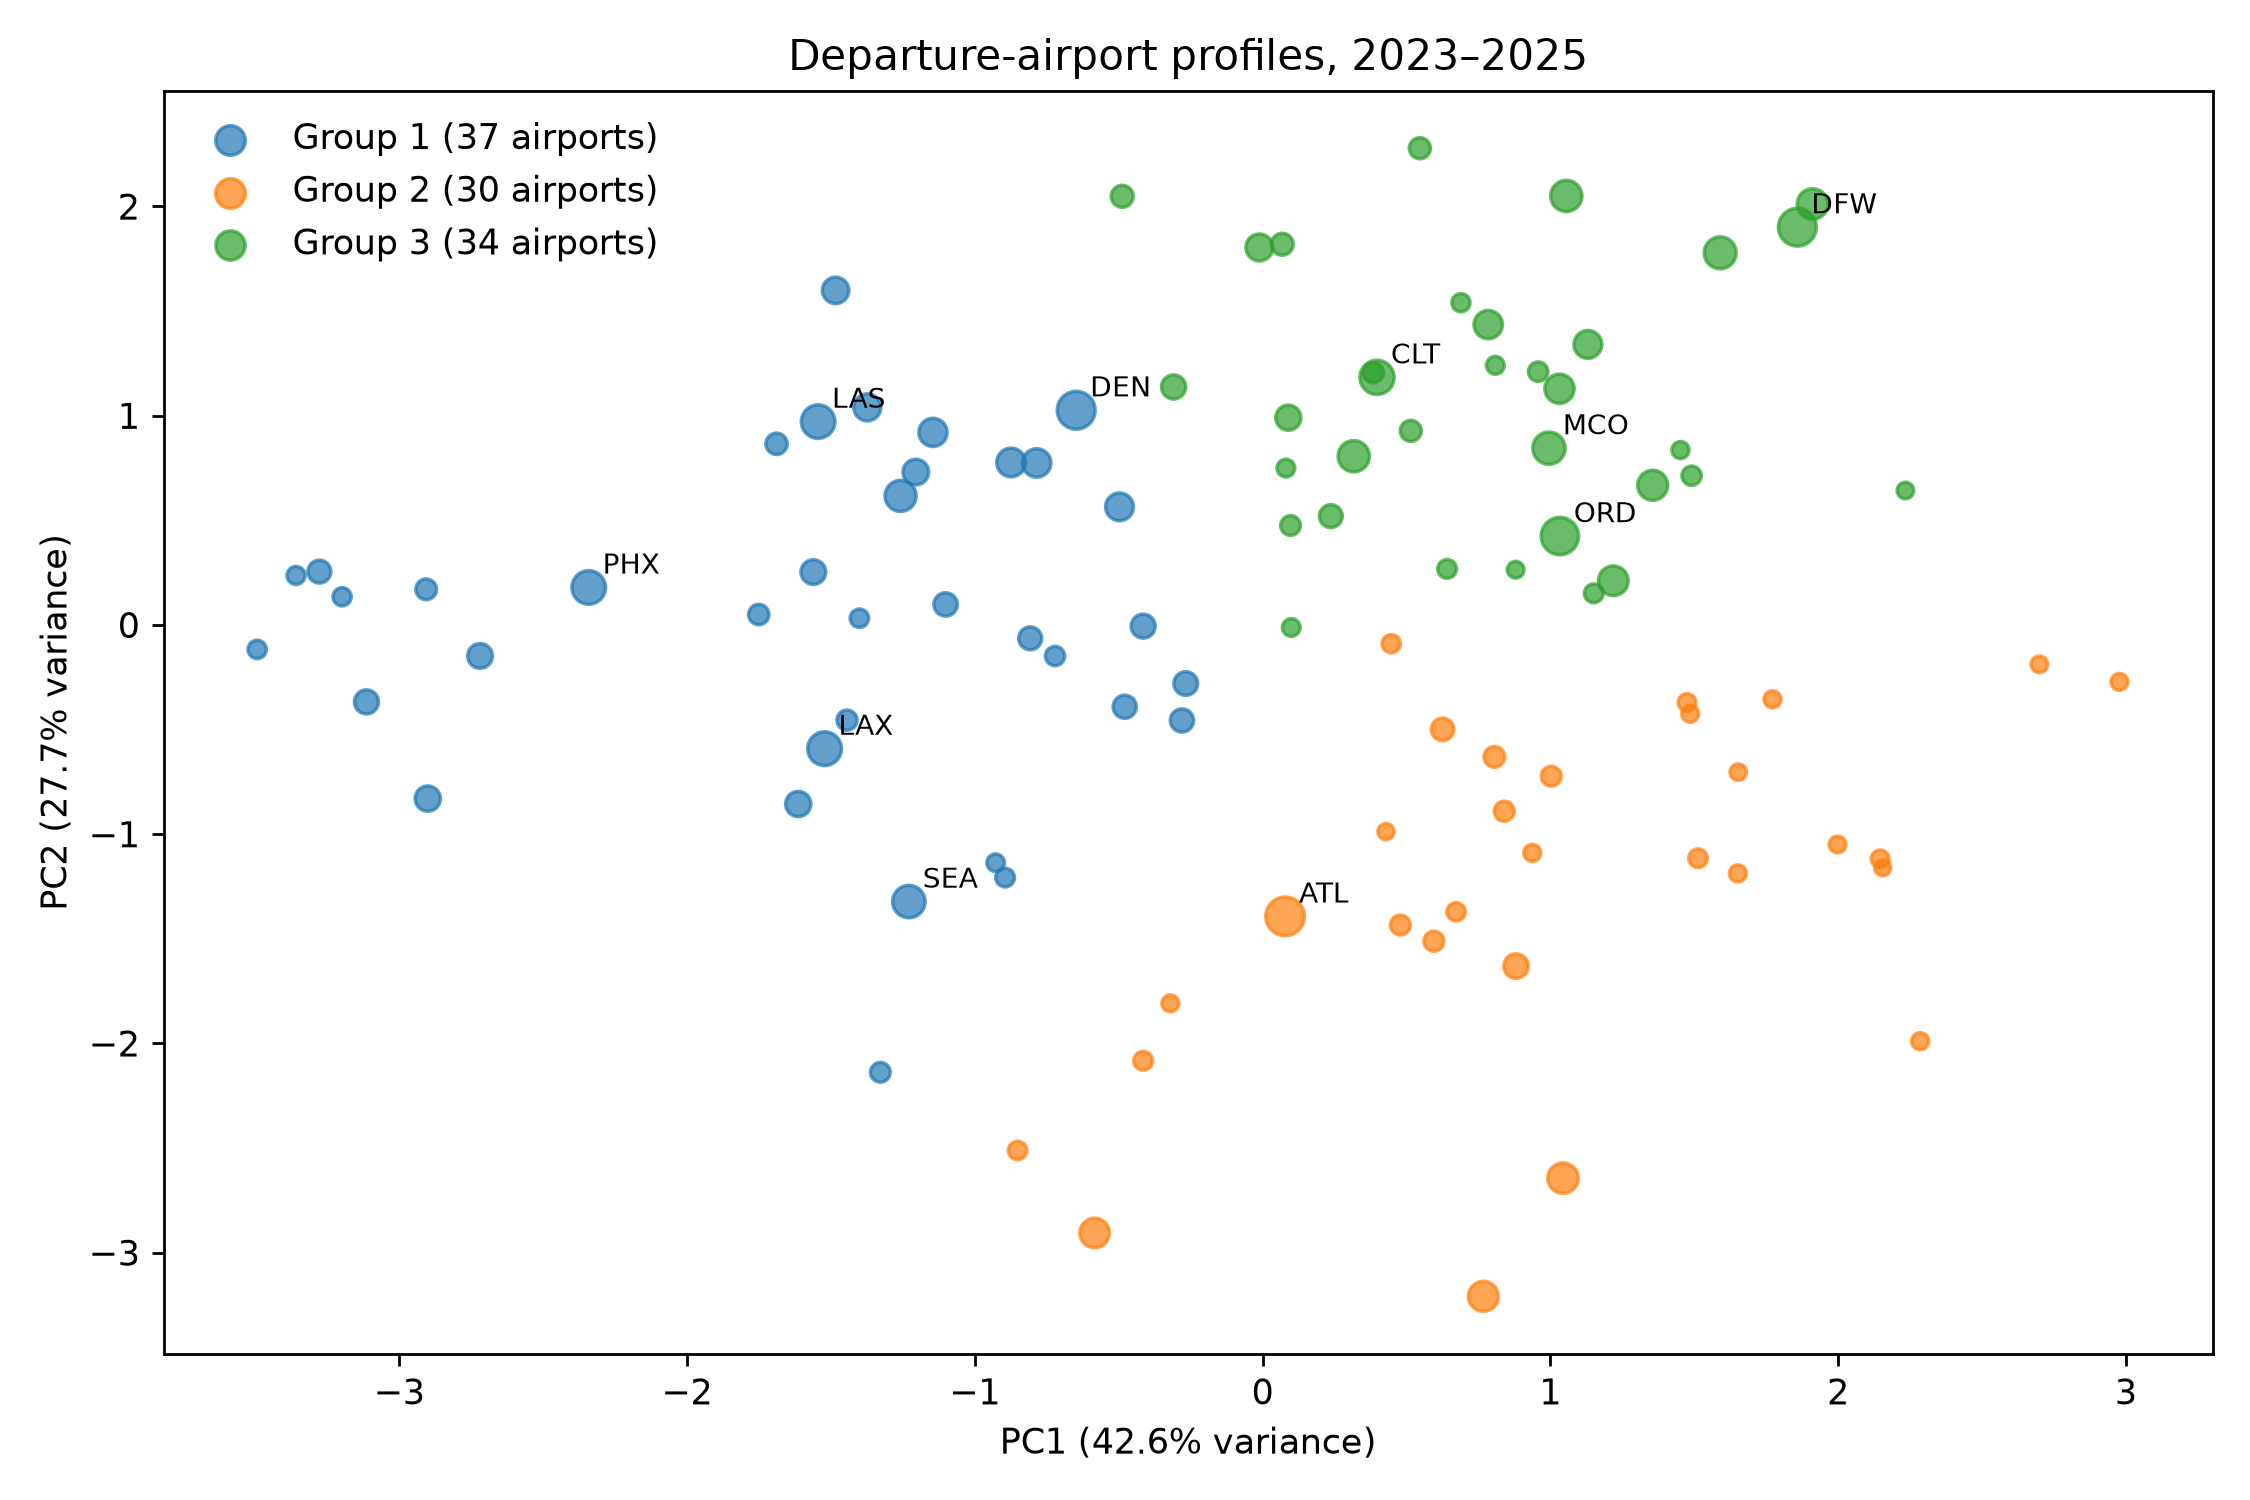

In [5]:
airports = airport_profiles(db, source)
airports.to_csv(OUT_DIR / 'airport_profiles_all.csv', index=False)
eligible, cluster_summary, k_diagnostics = cluster_airports(airports, OUT_DIR)
print('K choice:')
print(k_diagnostics.round(3).to_string(index=False))
print('\nCluster summary:')
print(cluster_summary.round(3).to_string(index=False))
print('\nThreshold sensitivity:')
print(pd.read_csv(OUT_DIR / 'cluster_sensitivity.csv').round(3).to_string(index=False))

## 3 · Association-rule mining

The six predeparture dimensions are season, scheduled departure period, week type, distance band, reporting airline and origin state. We enumerate all **observed** combinations of one to three dimensions. We select rules using 2023–2024 only: joint support ≥0.5%, at least 50,000 antecedent flights, and lift ≥1.20. Year 2025 does not determine the ranking in this pipeline; because earlier exploration informed feature choices, it is a temporal robustness check rather than a blind external test. `support=P(conditions and delay)`, `confidence=P(delay | conditions)`, `lift=confidence / overall delay rate`. Risk difference compares each condition with flights that do not meet it.

In [6]:
def build_rule_cube(db: duckdb.DuckDBPyConnection, source: str) -> pd.DataFrame:
    """One scan creates a small transaction cube for exhaustive 1-3-item mining."""
    cube = db.execute(f"""
        SELECT Year AS year,
               CASE WHEN Month IN (12,1,2) THEN 'winter'
                    WHEN Month IN (3,4,5) THEN 'spring'
                    WHEN Month IN (6,7,8) THEN 'summer' ELSE 'autumn' END AS season,
               CASE WHEN CRSDepHour BETWEEN 0 AND 5 THEN 'overnight'
                    WHEN CRSDepHour BETWEEN 6 AND 11 THEN 'morning'
                    WHEN CRSDepHour BETWEEN 12 AND 17 THEN 'afternoon'
                    ELSE 'evening' END AS dep_period,
               CASE WHEN DayOfWeek IN (6,7) THEN 'weekend' ELSE 'weekday' END AS week_type,
               CASE WHEN Distance < 500 THEN 'short'
                    WHEN Distance < 1000 THEN 'medium' ELSE 'long' END AS distance_band,
               Reporting_Airline AS airline, OriginState AS origin_state,
               count(*) AS n, count(*) FILTER (WHERE ArrDel15=1) AS delayed
        FROM {source}
        WHERE Cancelled=0 AND Diverted=0 AND ArrDel15 IS NOT NULL
          AND CRSDepHour BETWEEN 0 AND 23
          AND Month BETWEEN 1 AND 12 AND DayOfWeek BETWEEN 1 AND 7
          AND Distance IS NOT NULL AND Reporting_Airline IS NOT NULL
          AND OriginState IS NOT NULL
        GROUP BY ALL
    """).df()
    return cube


def mine_rules(cube: pd.DataFrame, out: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Enumerate observed itemsets, select on training only, attach 2025 results."""
    train = cube.loc[cube.year.isin([2023, 2024])]
    test = cube.loc[cube.year == 2025]
    n_train, d_train = int(train.n.sum()), int(train.delayed.sum())
    n_test, d_test = int(test.n.sum()), int(test.delayed.sum())
    rows = []
    total_candidates = 0
    for size in (1, 2, 3):
        for dims in itertools.combinations(RULE_DIMENSIONS, size):
            a = train.groupby(list(dims), dropna=False)[["n", "delayed"]].sum().reset_index()
            b = test.groupby(list(dims), dropna=False)[["n", "delayed"]].sum().reset_index()
            both = a.merge(b, on=list(dims), how="left", suffixes=("_train", "_test"))
            both[["n_test", "delayed_test"]] = both[["n_test", "delayed_test"]].fillna(0)
            total_candidates += len(both)
            for row in both.itertuples(index=False):
                values = [getattr(row, d) for d in dims]
                nt, dt = int(row.n_train), int(row.delayed_train)
                ns, ds = int(row.n_test), int(row.delayed_test)
                joint_support = dt / n_train
                if joint_support < .005 or nt < 50_000:
                    continue
                confidence = dt / nt
                lift = confidence / (d_train / n_train)
                if lift < 1.20:
                    continue
                rule = " & ".join(f"{d}={v}" for d, v in zip(dims, values))
                risk_unexposed_train = (d_train - dt) / (n_train - nt)
                risk_unexposed_test = (d_test - ds) / (n_test - ns) if ns < n_test else np.nan
                rows.append({
                    "antecedent": rule, "item_count": size,
                    "train_antecedent_n": nt, "train_delayed_n": dt,
                    "train_antecedent_coverage": nt / n_train,
                    "train_support": joint_support, "train_confidence": confidence,
                    "train_lift": lift,
                    "train_risk_difference_pp": 100 * (confidence - risk_unexposed_train),
                    "test_antecedent_n": ns, "test_delayed_n": ds,
                    "test_support": ds / n_test,
                    "test_confidence": ds / ns if ns else np.nan,
                    "test_lift": (ds / ns) / (d_test / n_test) if ns else np.nan,
                    "test_risk_difference_pp": 100 * ((ds / ns) - risk_unexposed_test) if ns else np.nan,
                })
    result = pd.DataFrame(rows).sort_values(["train_lift", "train_support"], ascending=False)
    result.to_csv(out / "association_rules.csv", index=False)
    meta = pd.DataFrame([{"candidate_itemsets": total_candidates,
                          "selected_rules": len(result),
                          "min_joint_support": .005, "min_train_antecedent_n": 50_000,
                          "min_train_lift": 1.20,
                          "train_flights": n_train, "test_flights": n_test,
                          "train_delay_baseline": d_train / n_train,
                          "test_delay_baseline": d_test / n_test}])
    meta.to_csv(out / "rule_mining_audit.csv", index=False)
    return result, meta

In [7]:
cube = build_rule_cube(db, source)
cube.to_csv(OUT_DIR / 'rule_cube.csv', index=False)
rules, rule_audit = mine_rules(cube, OUT_DIR)
print('Search audit:')
print(rule_audit.to_string(index=False))
print('\nTop mined rules:')
cols = ['antecedent','train_antecedent_n','train_support','train_confidence','train_lift','test_confidence','test_lift']
print(rules[cols].head(12).round(3).to_string(index=False))

Search audit:
 candidate_itemsets  selected_rules  min_joint_support  min_train_antecedent_n  min_train_lift  train_flights  test_flights  train_delay_baseline  test_delay_baseline
              12757             107              0.005                   50000             1.2       13708650       6879484              0.206925             0.223075

Top mined rules:
                                               antecedent  train_antecedent_n  train_support  train_confidence  train_lift  test_confidence  test_lift
          season=summer & dep_period=evening & airline=WN              178590          0.006             0.445       2.149            0.430      1.927
season=summer & dep_period=evening & distance_band=medium              296736          0.009             0.411       1.987            0.432      1.937
   season=summer & dep_period=evening & week_type=weekend              230864          0.007             0.402       1.945            0.398      1.786
  season=summer & dep_period=e

## 4 · Temporal and within-stratum checks

The broad summer-evening pattern is reported by year, separately from the ranked mined rules. For a limited confounding check, summer evening flights are compared with other summer hours **within the same month, departure airport and airline**. Each timing group needs at least 30 flights per stratum. This remains descriptive; route and weather mix may still differ.

In [8]:
def summer_evening_validation(db: duckdb.DuckDBPyConnection, source: str, out: Path) -> pd.DataFrame:
    """Previously observed temporal finding, separate from mined top rules."""
    table = db.execute(f"""
        SELECT Year AS year,
               CASE WHEN Month BETWEEN 6 AND 8 THEN 1 ELSE 0 END AS summer,
               CASE WHEN CRSDepHour BETWEEN 18 AND 23 THEN 1 ELSE 0 END AS evening,
               count(*) AS n, count(*) FILTER (WHERE ArrDel15=1) AS delayed
        FROM {source}
        WHERE Cancelled=0 AND Diverted=0 AND ArrDel15 IS NOT NULL
        GROUP BY ALL ORDER BY ALL
    """).df()
    table["delay_rate"] = table.delayed / table.n
    table.to_csv(out / "summer_evening_by_year.csv", index=False)
    return table


def stratified_evening_validation(db: duckdb.DuckDBPyConnection, source: str,
                                  out: Path) -> pd.DataFrame:
    """Within summer, compare evening with other hours in the same month/airport/airline.

    This is a descriptive stratified comparison, not a causal estimate. Strata
    with fewer than 30 flights in either timing group are excluded.
    """
    data = db.execute(f"""
        SELECT Year AS y, Month AS m, Origin AS airport,
               Reporting_Airline AS airline,
               CAST(CRSDepHour BETWEEN 18 AND 23 AS INTEGER) AS evening,
               count(*) AS n, count(*) FILTER (WHERE ArrDel15=1) AS delayed
        FROM {source}
        WHERE Month BETWEEN 6 AND 8 AND Cancelled=0 AND Diverted=0
          AND ArrDel15 IS NOT NULL AND CRSDepHour BETWEEN 0 AND 23
        GROUP BY ALL
    """).df()
    rows = []
    for year, group in data.groupby("y"):
        table = group.pivot_table(index=["m", "airport", "airline"], columns="evening",
                                  values=["n", "delayed"], aggfunc="sum").fillna(0)
        table.columns = [f"{metric}_{flag}" for metric, flag in table.columns]
        table = table.loc[(table.n_1 >= 30) & (table.n_0 >= 30)].copy()
        table["risk_difference"] = table.delayed_1 / table.n_1 - table.delayed_0 / table.n_0
        exposed_total = int(group.loc[group.evening == 1, "n"].sum())
        rows.append({
            "year": int(year), "eligible_strata": len(table),
            "evening_flights_covered": int(table.n_1.sum()),
            "evening_coverage": float(table.n_1.sum() / exposed_total),
            "exposed_weighted_risk_difference_pp":
                float(100 * np.average(table.risk_difference, weights=table.n_1)),
            "fraction_strata_positive": float((table.risk_difference > 0).mean()),
        })
    result = pd.DataFrame(rows)
    result.to_csv(out / "stratified_evening_check.csv", index=False)
    return result

In [9]:
temporal = summer_evening_validation(db, source, OUT_DIR)
stratified = stratified_evening_validation(db, source, OUT_DIR)
print('Summer × evening, by year:')
print(temporal.round(3).to_string(index=False))
print('\nWithin-month/airport/airline summer comparison:')
print(stratified.round(3).to_string(index=False))

Summer × evening, by year:
 year  summer  evening       n  delayed  delay_rate
 2023       0        0 3858587   652041       0.169
 2023       0        1 1144812   286871       0.251
 2023       1        0 1327498   291658       0.220
 2023       1        1  412506   156129       0.378
 2024       0        0 4001001   685371       0.171
 2024       0        1 1144733   290973       0.254
 2024       1        0 1395721   308729       0.221
 2024       1        1  423792   164893       0.389
 2025       0        0 3961909   746919       0.189
 2025       0        1 1111559   307382       0.277
 2025       1        0 1393387   317681       0.228
 2025       1        1  412629   162656       0.394

Within-month/airport/airline summer comparison:
 year  eligible_strata  evening_flights_covered  evening_coverage  exposed_weighted_risk_difference_pp  fraction_strata_positive
 2023             1636                   387157             0.939                               15.183                 

## 5 · Figures and interpretation

Rule plots show both support–confidence and held-out lift. Read clusters as exploratory profiles: the silhouette advantage of k=3 is small, and cluster membership changes for some lower-volume airports. Read rule lift as an association, not a causal effect. Full interpretation and the six handoff elements are in `member2_report.md`.

In [10]:
def rule_plots(rules: pd.DataFrame, out: Path) -> None:
    short_names = {
        "season=summer": "Summer", "dep_period=evening": "evening",
        "distance_band=medium": "500–999 mi", "distance_band=long": "1,000+ mi",
        "distance_band=short": "<500 mi", "week_type=weekend": "weekend",
        "week_type=weekday": "weekday", "airline=WN": "WN", "origin_state=FL": "Florida",
    }

    def display_rule(rule: str) -> str:
        return " + ".join(short_names.get(part, part) for part in rule.split(" & "))

    shown = rules.head(8).iloc[::-1].copy()
    shown["display"] = shown.antecedent.map(display_rule)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(shown.display, shown.train_lift, label="2023–24", color="#3867a6")
    ax.scatter(shown.test_lift, shown.display, label="2025", color="#d45d39", zorder=3)
    ax.axvline(1, color="black", linewidth=.8)
    ax.set(xlabel="Lift for arrival delay >=15 min", title="Top mined rules: 2023–24 ranking and 2025 temporal check")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(out / "association_rules.png", dpi=250)
    plt.close(fig)

    shown = rules.head(7)
    fig, ax = plt.subplots(figsize=(10, 6.5))
    points = ax.scatter(shown.train_support * 100, shown.train_confidence * 100,
                        c=shown.train_lift, s=100 + 50 * shown.item_count,
                        cmap="viridis", edgecolor="white")
    for row in shown.itertuples():
        label = display_rule(row.antecedent)
        ax.annotate(label, (row.train_support * 100, row.train_confidence * 100),
                    xytext=(5, 4), textcoords="offset points", fontsize=7)
    ax.set(xlabel="Support (% of all executed flights)",
           ylabel="Confidence (% delayed given conditions)",
           title="Mined flight-delay rules, 2023–2024")
    ax.set_xlim(0.4, 3.5)
    ax.set_ylim(34, 46)
    fig.colorbar(points, ax=ax, label="Lift")
    fig.tight_layout()
    fig.savefig(out / "rule_support_confidence.png", dpi=250)
    plt.close(fig)

Figures saved to member2_results


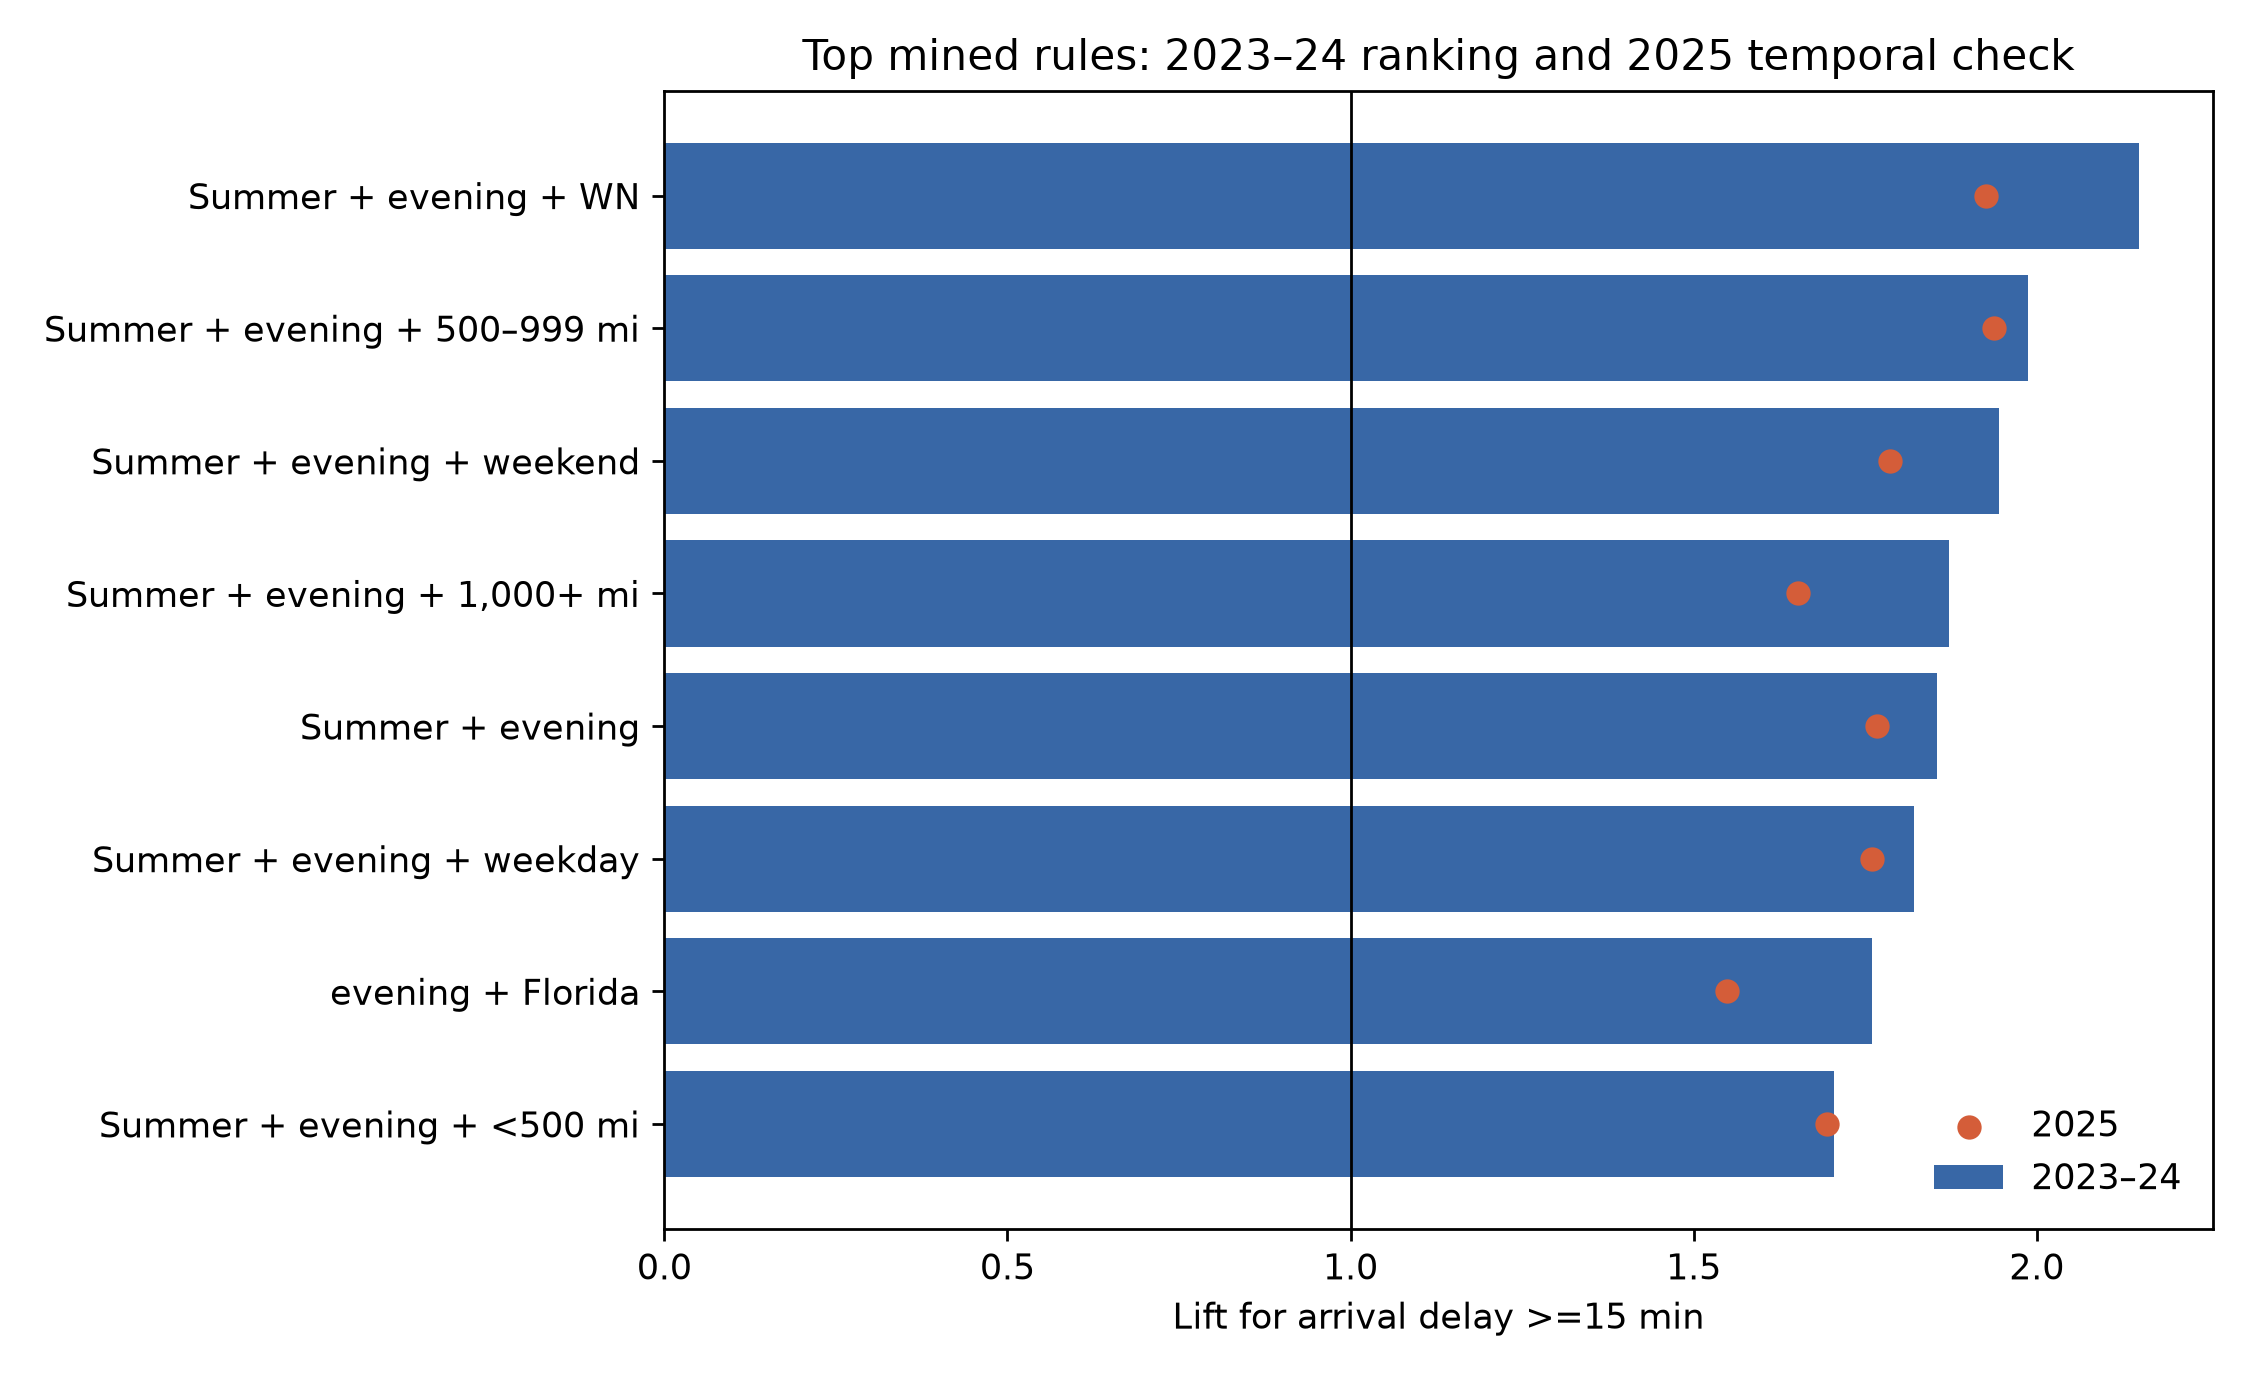

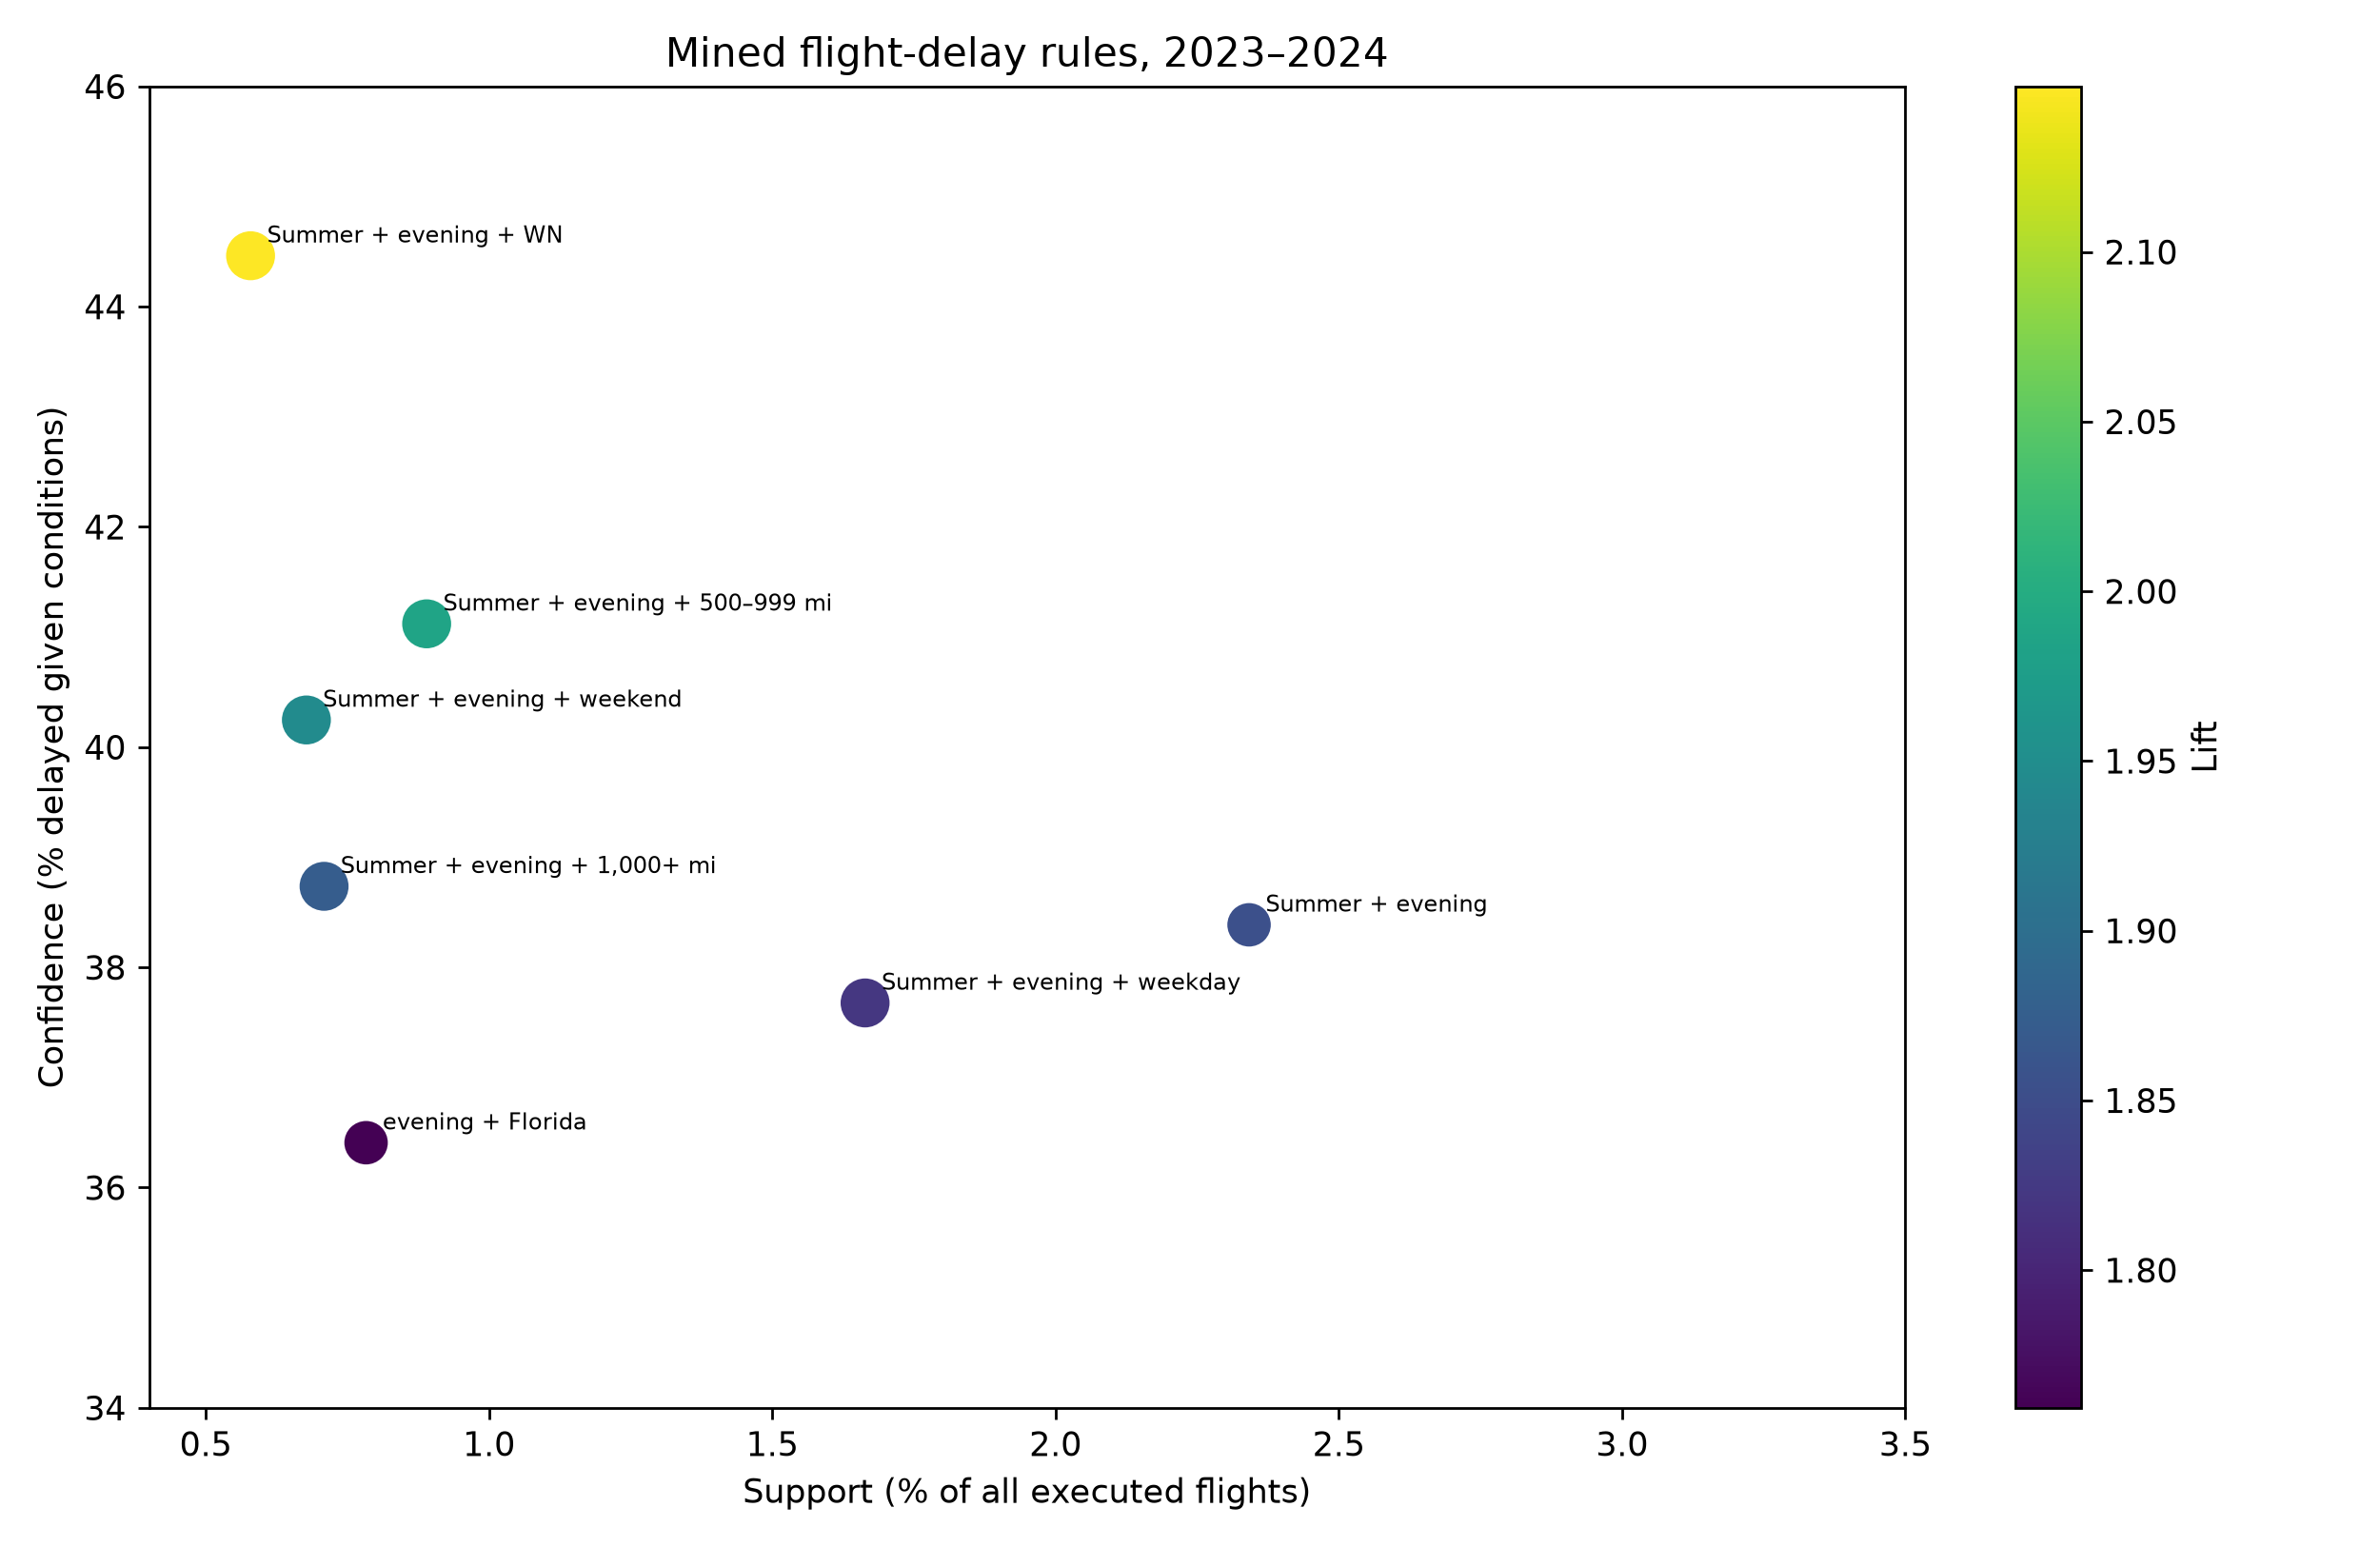

In [11]:
rule_plots(rules, OUT_DIR)
print('Figures saved to', OUT_DIR)